# Modelo de referencia: regresión logística
## Proyecto final de Ciencia de Datos · *Bank Marketing* (UCI)

**Instructor:** M. en C. Benito Samuel López Razo · **Autores:** _(escribe aquí tu nombre y el de tu equipo)_ · **Semilla global:** 42

Este notebook vive en la carpeta `modelos/` y es **independiente** del notebook de la Parte 1 (datos y preparación). Todo lo compartido (carga de datos, división, validación cruzada y funciones de evaluación) está en `utils_proyecto.py`, para que **todos los modelos se comparen bajo exactamente las mismas reglas**.

La regresión logística es el **pivote**: un modelo simple, lineal e interpretable contra el cual se compara todo lo demás. Si un modelo más complejo (Naive Bayes, SVM o red neuronal) no la supera claramente, su complejidad no se justifica.

**Índice**

1. Reglas comunes y carga de datos
2. Espacio de búsqueda e hiperparámetros
3. Búsqueda en malla con validación cruzada
4. Evaluación en el conjunto de prueba
5. Variabilidad entre folds
6. Coeficientes del modelo
7. Interpretación (borrador)

## 1. Reglas comunes y carga de datos

Estas reglas se definen una sola vez en `utils_proyecto.py` y se aplican igual a todos los modelos:

| Decisión | Qué se hace | Por qué |
|---|---|---|
| Datos | Misma limpieza y misma división 70 / 15 / 15 estratificada con `SEED = 42` que la Parte 1 | Todos los modelos ven exactamente los mismos conjuntos |
| Preprocesamiento | Dentro de un `Pipeline` con `clone(preprocesador)` | En cada fold, el escalado y la codificación se ajustan solo con los folds de entrenamiento: no hay fuga hacia el fold que se evalúa |
| Ajuste de hiperparámetros | `GridSearchCV` con validación cruzada estratificada de 5 folds **sobre train** | Lo pide el PDF; estratificada porque la clase `yes` es solo el 11.7 % |
| Métrica para elegir hiperparámetros | AUC-PR (`average_precision`) | Resume la calidad en todos los umbrales y no se infla con la clase mayoritaria como la exactitud |
| Umbral de decisión | Se elige con el conjunto de **validación** (el que maximiza F1) y se aplica en *test* | Con clases desbalanceadas, 0.5 casi nunca es el mejor umbral; así la validación tiene un papel y *test* se usa **una sola vez** |
| Métricas en test | Exactitud, precisión, sensibilidad, F1, AUC-ROC, AUC-PR, matriz de confusión y curvas ROC y precisión-recall | Las que pide el PDF (con curva precisión-recall por el desbalance) |
| Variabilidad | Validación cruzada repetida 5 × 3 sobre train: media y desviación estándar | Permite saber si las diferencias entre modelos son reales; las particiones son las mismas para todos los modelos |

La celda siguiente importa lo necesario y carga los datos. **La tabla que imprime debe coincidir con la sección 6 de la Parte 1** (31,647 / 6,782 / 6,782 filas y 11.70 % de `yes` en cada conjunto).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

import utils_proyecto as up

SEED = up.SEED
d = up.cargar_datos()          # d.X_train, d.y_train, d.X_val, d.y_val, d.X_test, d.y_test, d.preprocesador

display(up.resumen_datos(d))

,filas,% clase 'yes'
train,31647,11.70
validation,6782,11.69
test,6782,11.69


## 2. Espacio de búsqueda e hiperparámetros

**Hiperparámetros ajustados (espacio de búsqueda que pide reportar el PDF):**

- `C`: inverso de la fuerza de regularización L2 (más pequeño = más regularización). Valores: 0.001, 0.01, 0.1, 1, 10 y 100.
- `class_weight`: `None` (sin ponderar) o `"balanced"` (da más peso a la clase `yes`, la minoritaria).

Son 6 × 2 = 12 combinaciones × 5 folds = 60 ajustes. `max_iter = 2000` asegura que el optimizador converja.

## 3. Búsqueda en malla con validación cruzada

Se arma un `Pipeline` (preprocesador + modelo) para que el escalado y la codificación se ajusten **dentro de cada fold**, solo con los datos de entrenamiento del fold. Se le pasa `X_train` **sin transformar**. Al final se guarda la tabla completa de combinaciones en `resultados/`.

In [2]:
pipe_lr = Pipeline([
    ("prep", clone(d.preprocesador)),
    ("modelo", LogisticRegression(max_iter=2000, random_state=SEED)),
])

espacio_lr = {
    "modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "modelo__class_weight": [None, "balanced"],
}

busqueda_lr = GridSearchCV(pipe_lr, espacio_lr, scoring=up.METRICA_CV, cv=up.CV, n_jobs=-1)
busqueda_lr.fit(d.X_train, d.y_train)

print("Mejores hiperparámetros:", up.formatear_params(busqueda_lr.best_params_))
print(f"{up.METRICA_CV} medio en CV: {busqueda_lr.best_score_:.4f}")

res = busqueda_lr.cv_results_
cv_lr = pd.DataFrame({
    "C": [p["modelo__C"] for p in res["params"]],
    "class_weight": ["ninguno" if p["modelo__class_weight"] is None else p["modelo__class_weight"]
                     for p in res["params"]],
    "AUC-PR medio": res["mean_test_score"],
    "desv. estándar": res["std_test_score"],
    "ranking": res["rank_test_score"],
}).sort_values("ranking").reset_index(drop=True)

display(cv_lr.round(4))
up.guardar_tabla(cv_lr, "tabla_lr_busqueda_cv")

Mejores hiperparámetros: C = 0.1, class_weight = None
average_precision medio en CV: 0.4087


,C,class_weight,AUC-PR medio,desv. estándar,ranking
0,0.100,ninguno,0.4087,0.0181,1
1,1.000,ninguno,0.4082,0.0185,2
2,100.000,ninguno,0.4081,0.0185,3
3,10.000,ninguno,0.4081,0.0185,4
4,0.100,balanced,0.4053,0.0176,5
5,10.000,balanced,0.4050,0.0180,6
6,100.000,balanced,0.4050,0.0180,7
7,1.000,balanced,0.4050,0.0180,8
8,0.010,balanced,0.4028,0.0171,9
9,0.010,ninguno,0.4019,0.0183,10


Tabla guardada: resultados/tabla_lr_busqueda_cv.csv


Gráfica del efecto de `C` y `class_weight` sobre el AUC-PR, con barras de desviación estándar entre folds (buena figura para el reporte).

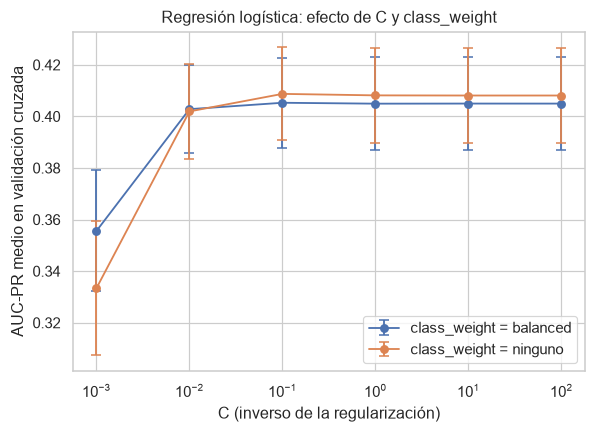

Figura guardada: figuras/fig_lr_busqueda_cv.png


In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
for cw, grupo in cv_lr.groupby("class_weight"):
    grupo = grupo.sort_values("C")
    ax.errorbar(grupo["C"].astype(float), grupo["AUC-PR medio"], yerr=grupo["desv. estándar"],
                marker="o", capsize=3, label=f"class_weight = {cw}")
ax.set_xscale("log")
ax.set_xlabel("C (inverso de la regularización)")
ax.set_ylabel("AUC-PR medio en validación cruzada")
ax.set_title("Regresión logística: efecto de C y class_weight")
ax.legend()
plt.show()
up.guardar(fig, "fig_lr_busqueda_cv")

## 4. Evaluación en el conjunto de prueba

`evaluar_modelo()` elige el umbral con el conjunto de **validación**, evalúa **una sola vez** en *test* y genera matriz de confusión, curva ROC y curva precisión-recall. Además guarda en `resultados/` las métricas (`lr_metricas_test.json`) y las predicciones (`lr_predicciones_test.csv`): el notebook de comparación final y el análisis de errores leerán esos archivos.

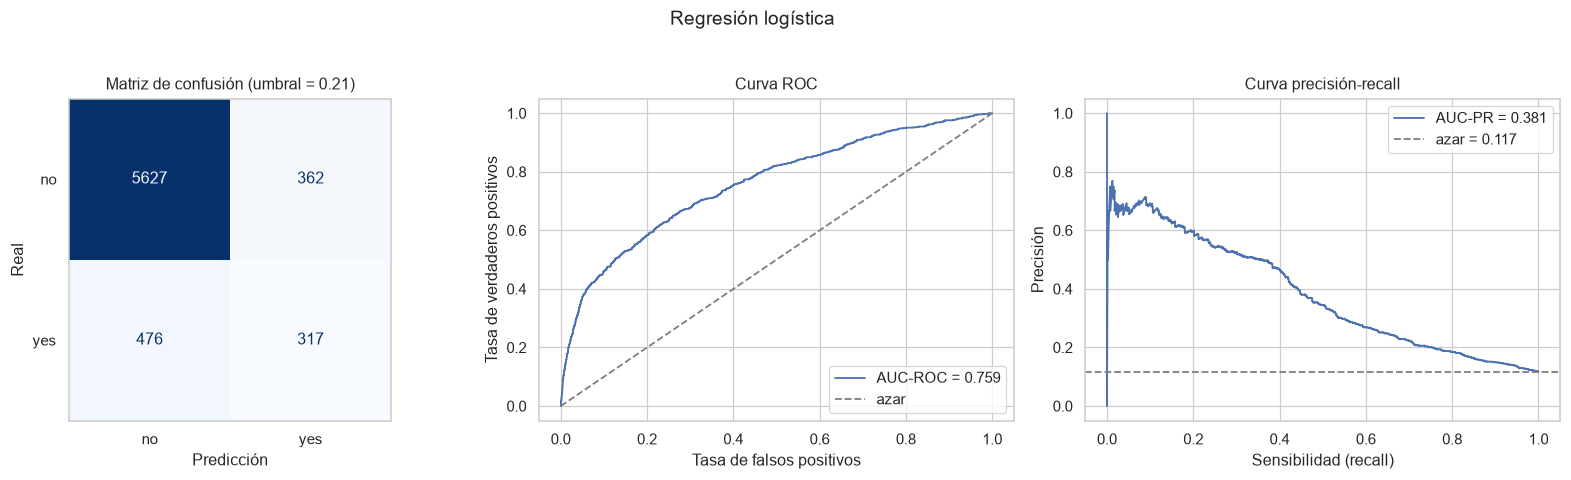

Figura guardada: figuras/fig_lr_evaluacion.png
Métricas guardadas: resultados/lr_metricas_test.json y resultados/lr_predicciones_test.csv


,test
umbral,0.2142
exactitud,0.8764
precisión,0.4669
sensibilidad,0.3997
F1,0.4307
AUC-ROC,0.7591
AUC-PR,0.3813


In [4]:
mejor_lr = busqueda_lr.best_estimator_

metricas_lr = up.evaluar_modelo("Regresión logística", mejor_lr, "lr", d)
display(metricas_lr.to_frame("test"))

## 5. Variabilidad entre folds

Validación cruzada repetida 5 × 3 sobre *train*, con el mejor modelo. La desviación estándar es el "ruido" contra el cual se medirá si otro modelo mejora de verdad. Los puntajes por fold se guardan en `resultados/lr_cv_scores.csv` (se usarán para comparar modelos por pares).

In [5]:
tabla_var_lr = up.variabilidad_cv("Regresión logística", mejor_lr, "lr", d)
display(tabla_var_lr)

Tabla guardada: resultados/tabla_lr_variabilidad_cv.csv


,media,desv. estándar
AUC-PR,0.4091,0.0124
AUC-ROC,0.7659,0.0079


## 6. Coeficientes del modelo

Muestra qué variables pesan más (coeficientes y *odds ratios*); es útil para la discusión. Las numéricas están estandarizadas, así que su coeficiente es por cada desviación estándar; las categóricas son *one-hot*, así que se leen contra la categoría de referencia.

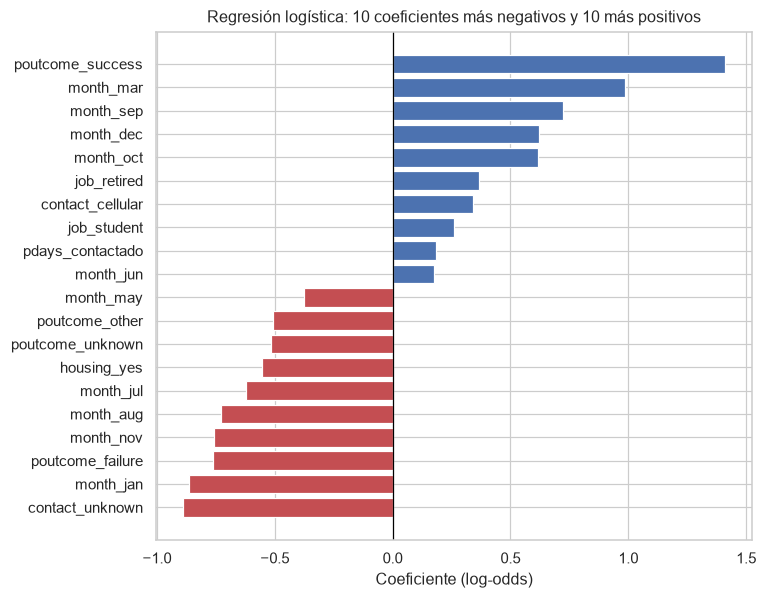

Figura guardada: figuras/fig_lr_coeficientes.png
Más asociadas a NO contratar:


,coeficiente,odds ratio
contact_unknown,-0.891,0.410
month_jan,-0.866,0.421
poutcome_failure,-0.762,0.467
month_nov,-0.759,0.468
month_aug,-0.727,0.483


Más asociadas a contratar:


,coeficiente,odds ratio
poutcome_success,1.411,4.102
month_mar,0.985,2.678
month_sep,0.724,2.062
month_dec,0.620,1.860
month_oct,0.619,1.857


Tabla guardada: resultados/tabla_lr_coeficientes.csv


In [6]:
nombres_variables = mejor_lr.named_steps["prep"].get_feature_names_out()
coef_lr = pd.Series(mejor_lr.named_steps["modelo"].coef_[0], index=nombres_variables).sort_values()

top_coef = pd.concat([coef_lr.head(10), coef_lr.tail(10)])
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top_coef.index, top_coef.values, color=np.where(top_coef.values > 0, "#4C72B0", "#C44E52"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coeficiente (log-odds)")
ax.set_title("Regresión logística: 10 coeficientes más negativos y 10 más positivos")
plt.show()
up.guardar(fig, "fig_lr_coeficientes")

odds = pd.DataFrame({"coeficiente": coef_lr, "odds ratio": np.exp(coef_lr)}).round(3)
print("Más asociadas a NO contratar:")
display(odds.head(5))
print("Más asociadas a contratar:")
display(odds.tail(5).iloc[::-1])
up.guardar_tabla(odds.sort_values("coeficiente"), "tabla_lr_coeficientes")

## 7. Interpretación (borrador con tus datos)

Borrador con los resultados de una corrida sobre `bank-full.csv`. **Verifica que tus números coincidan y reescríbelo con tus palabras para el reporte.**

- **Ajuste:** la mejor combinación fue `C = 0.1` sin ponderar clases (AUC-PR en CV de 0.409). Entre la mejor y la novena combinación la diferencia (0.403–0.409) es **mucho menor que la desviación estándar entre folds (≈ 0.018)**, así que en la práctica da lo mismo cuál se elija. Solo la regularización extrema (`C = 0.001`) empeora claramente. `class_weight` casi no cambia el AUC-PR porque esta métrica depende del orden de las probabilidades, no del umbral; ese efecto se corrige con el umbral elegido en validación.
- **Resultado en test** (umbral = 0.21): exactitud 0.876, precisión 0.467, sensibilidad 0.400, F1 0.431, AUC-ROC 0.759 y AUC-PR 0.381. La exactitud es incluso **menor** que la de un clasificador que siempre responda `no` (88.3 %), lo que confirma que no sirve como métrica en este problema. De los 793 clientes que sí contratan, el modelo detecta 317 (sensibilidad de 40 %) y genera 362 falsos positivos.
- **Variabilidad:** en la validación cruzada repetida, AUC-PR = 0.409 ± 0.012 y AUC-ROC = 0.766 ± 0.008. Una mejora de otro modelo menor a ~0.01–0.02 en AUC-PR probablemente no es real.
- **Coeficientes:** lo más asociado a contratar es `poutcome_success` (odds ratio ≈ 4.1) y los meses de marzo, septiembre, diciembre y octubre; lo más asociado a no contratar es el contacto `unknown` (OR ≈ 0.41), `poutcome_failure`, enero, noviembre y agosto.
- **Contexto:** el desempeño es modesto porque se excluyó `duration` (sección 5.4 de la Parte 1). Es lo esperado y se presenta como un resultado realista, no como una falla.